# Ejercicio 2: selección de features para clasificación de diagnósticos

Resolución basada en el estilo del ejercicio 1 adjunto: exploración con pandas, correlaciones, `selected_features`, `StandardScaler`, `Pipeline` y selección con `SelectKBest`. Se reemplaza la regresión por `MLPClassifier` y se agregan dos métodos de selección y una comparación controlada.

**Objetivo:** comparar las 30 variables del Breast Cancer Wisconsin (Diagnostic) con subconjuntos ANOVA e información mutua. Clase positiva: **maligno = 1**; benigno = 0. Uso exclusivamente educativo; no es una herramienta clínica.

Ejecutar las celdas en orden en Jupyter o Colab. Dependencias: numpy, pandas, matplotlib y scikit-learn. Si faltan, ejecutar `%pip install numpy pandas matplotlib scikit-learn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
SEED = 42
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.8.0


## 1. Carga y verificación de los datos

Se usa la copia del dataset UCI incluida en scikit-learn para que el notebook funcione sin conexión ni descarga adicional. Es el mismo problema de la consigna: 569 registros y 30 características. Fuente original: https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic (CC BY 4.0).

En esta copia, el target original codifica maligno como 0. Se invierte expresamente para que recall, precisión y F1 se refieran a malignos. No se incluye el ID como predictor. Los nombres de columnas de scikit-learn difieren de los de `ucimlrepo`.

In [2]:
cancer = load_breast_cancer(as_frame=True)
X = cancer.data.copy().drop(columns=['ID', 'id'], errors='ignore')
y = (cancer.target == 0).astype(int).rename('Diagnosis')
assert X.shape == (569, 30)
assert set(y.unique()) == {0, 1}
assert X.isna().sum().sum() == 0
print('Dimensiones:', X.shape)
print('Clases (0 = benigno, 1 = maligno):')
display(y.value_counts().sort_index().to_frame('Cantidad'))
display(X.head())
X.info()

Dimensiones: (569, 30)
Clases (0 = benigno, 1 = maligno):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error            

,Cantidad
Diagnosis,
0,357
1,212


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Partición estratificada 60 % / 20 % / 20 %

Se mantienen las mismas particiones para todos los modelos. El análisis de escalas, correlaciones, rankings y estabilidad utiliza exclusivamente entrenamiento. Validación sirve para elegir el conjunto; prueba queda reservada para la evaluación final.

In [3]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)
display(pd.DataFrame({
    nombre: {'Registros': len(yy), 'Benignos': int((yy == 0).sum()),
             'Malignos': int((yy == 1).sum())}
    for nombre, yy in [('Entrenamiento', y_train), ('Validación', y_val), ('Prueba', y_test)]
}).T)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_test.index)

,Registros,Benignos,Malignos
Entrenamiento,341,214,127
Validación,114,71,43
Prueba,114,72,42


## 3. Escalas, correlación y redundancia

Cada medida tiene tres resúmenes: `mean` (media), `error` (error estándar) y `worst` (promedio de los tres valores mayores). Radio, perímetro y área describen aspectos relacionados del tamaño; textura describe variaciones de intensidad. La correlación permite detectar redundancia lineal, pero no prueba que dos variables sean intercambiables para la red.

In [4]:
rangos = X_train.describe().T
display(rangos)

,count,mean,std,min,25%,50%,75%,max
mean radius,341.0,14.163419,3.599320,6.981000,11.670000,13.340000,16.140000,27.42000
mean texture,341.0,19.428768,4.361160,9.710000,16.390000,18.900000,21.870000,39.28000
mean perimeter,341.0,92.172581,24.857806,43.790000,74.680000,86.100000,105.800000,186.90000
mean area,341.0,659.691789,360.073150,143.500000,417.200000,551.100000,809.800000,2501.00000
mean smoothness,341.0,0.095654,0.014271,0.064290,0.084730,0.095140,0.104400,0.16340
mean compactness,341.0,0.103103,0.053278,0.023440,0.062320,0.092180,0.130400,0.34540
mean concavity,341.0,0.087244,0.078981,0.000000,0.027120,0.058350,0.132100,0.42680
mean concave points,341.0,0.048194,0.039362,0.000000,0.019170,0.032500,0.070170,0.20120
mean symmetry,341.0,0.180586,0.027461,0.106000,0.161900,0.177900,0.195300,0.30400
mean fractal dimension,341.0,0.062508,0.006797,0.050240,0.057690,0.061300,0.065620,0.09744


,Variable 1,Variable 2,Correlacion_Real,Correlacion_Absoluta
1,mean perimeter,mean radius,0.997831,0.997831
251,worst perimeter,worst radius,0.993829,0.993829
3,mean area,mean radius,0.987064,0.987064
5,mean area,mean perimeter,0.986496,0.986496
273,worst area,worst radius,0.982267,0.982267
275,worst area,worst perimeter,0.976554,0.976554
233,worst perimeter,mean perimeter,0.975609,0.975609
190,worst radius,mean radius,0.974526,0.974526
192,worst radius,mean perimeter,0.974286,0.974286
231,worst perimeter,mean radius,0.970396,0.970396


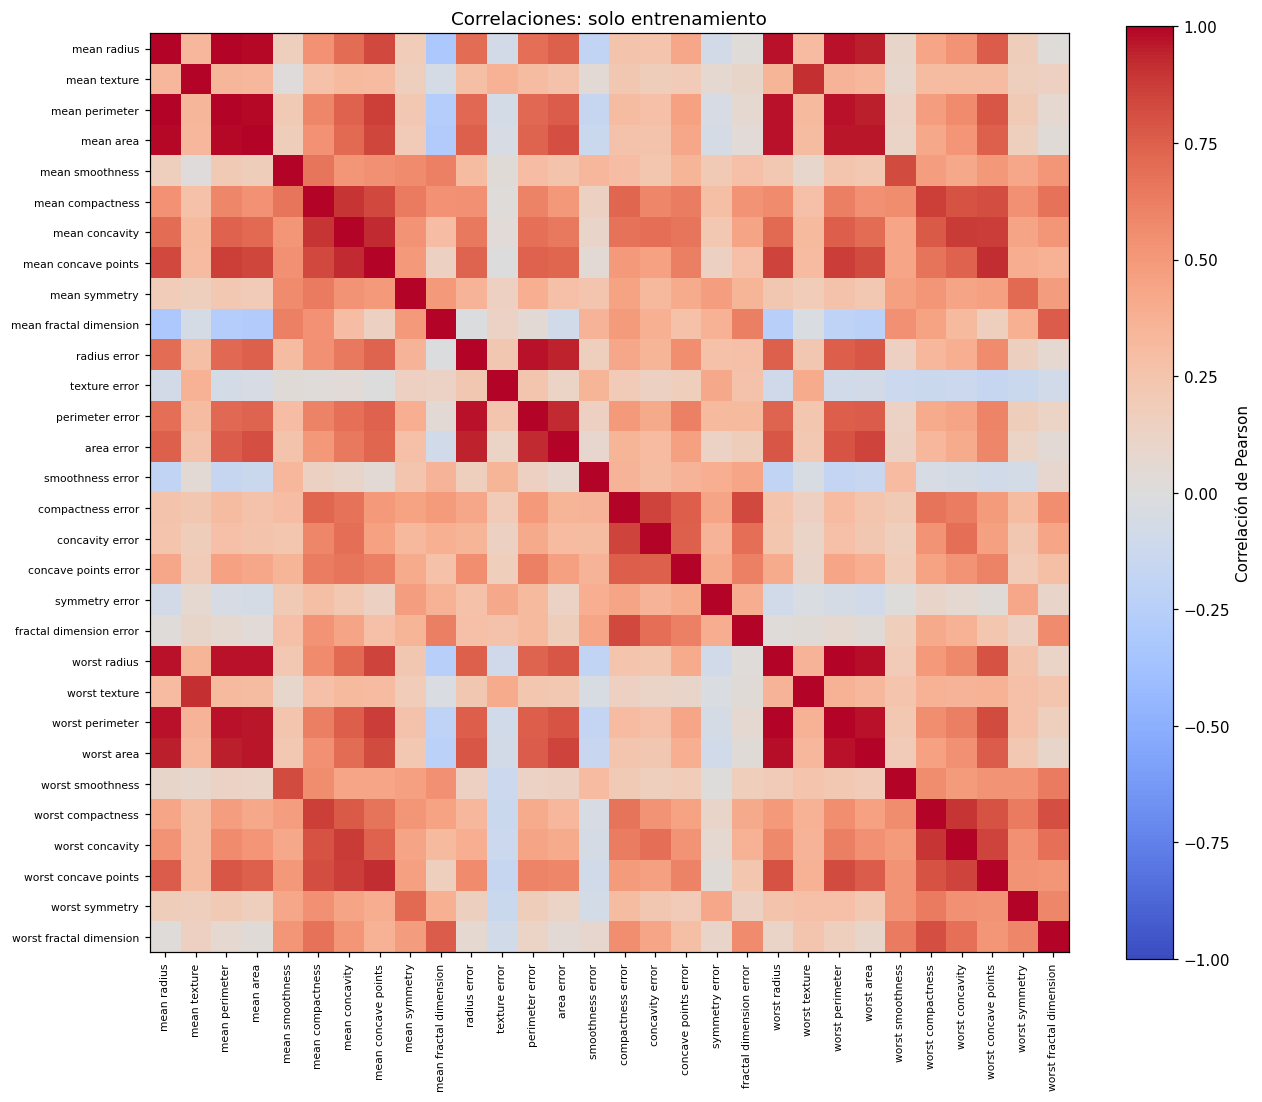

,mean radius,mean texture,mean perimeter,mean area,radius error,texture error,perimeter error,area error,worst radius,worst texture,worst perimeter,worst area
mean radius,1.00,0.33,1.00,0.99,0.70,-0.08,0.69,0.75,0.97,0.31,0.97,0.95
mean texture,0.33,1.00,0.34,0.33,0.29,0.37,0.30,0.26,0.35,0.91,0.36,0.33
mean perimeter,1.00,0.34,1.00,0.99,0.71,-0.07,0.71,0.76,0.97,0.32,0.98,0.95
mean area,0.99,0.33,0.99,1.00,0.74,-0.05,0.73,0.81,0.97,0.30,0.97,0.97
radius error,0.70,0.29,0.71,0.74,1.00,0.22,0.97,0.94,0.75,0.22,0.75,0.78
texture error,-0.08,0.37,-0.07,-0.05,0.22,1.00,0.24,0.12,-0.10,0.40,-0.09,-0.07
perimeter error,0.69,0.30,0.71,0.73,0.97,0.24,1.00,0.92,0.73,0.23,0.76,0.76
area error,0.75,0.26,0.76,0.81,0.94,0.12,0.92,1.00,0.79,0.22,0.79,0.85
worst radius,0.97,0.35,0.97,0.97,0.75,-0.10,0.73,0.79,1.00,0.36,0.99,0.98
worst texture,0.31,0.91,0.32,0.30,0.22,0.40,0.23,0.22,0.36,1.00,0.36,0.33


In [5]:
correlaciones = X_train.corr()
upper_tri = correlaciones.where(np.triu(np.ones(correlaciones.shape), k=1).astype(bool))
corr_df = upper_tri.unstack().dropna().reset_index()
corr_df.columns = ['Variable 1', 'Variable 2', 'Correlacion_Real']
corr_df['Correlacion_Absoluta'] = corr_df['Correlacion_Real'].abs()
top_20_corr = corr_df.sort_values('Correlacion_Absoluta', ascending=False).head(20)
display(top_20_corr)
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(correlaciones, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(30), X.columns, rotation=90, fontsize=7)
ax.set_yticks(range(30), X.columns, fontsize=7)
fig.colorbar(im, ax=ax, label='Correlación de Pearson')
ax.set_title('Correlaciones: solo entrenamiento')
plt.tight_layout()
plt.show()
familias = [c for c in X.columns if any(s in c for s in ['radius', 'perimeter', 'area', 'texture'])]
display(correlaciones.loc[familias, familias].round(2))

## 4. Dos subconjuntos candidatos

Se fija **k = 10** antes de evaluar validación. ANOVA (`f_classif`) mide separación univariada entre clases; información mutua detecta asociaciones más generales. Ambos seleccionan usando solo entrenamiento. No eliminan automáticamente redundancias.

Se conserva la arquitectura pequeña `(10, 5)` del ejercicio 1, con ReLU, semilla 42 y máximo de 8000 iteraciones. Se desactiva la parada temprana para usar la validación externa únicamente como comparación y evitar otra partición interna. Todos los candidatos comparten exactamente la configuración de la RNA y el escalado.

Todas (30) : ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
ANOVA (10) : ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']
Información mutua (10) : ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'area error', 'worst radius', 'worst perimeter', 'worst area', 'worst concave points']


,ANOVA (10),Información mutua (10)
worst concave points,575.592488,0.435871
worst perimeter,539.160471,0.447584
mean concave points,533.036776,0.456379
worst radius,517.155232,0.456509
mean perimeter,429.967442,0.415193
mean radius,402.342831,0.380655
worst area,386.710634,0.449047
mean area,353.575370,0.375320
mean concavity,325.497432,0.346691
worst concavity,230.803322,0.289793


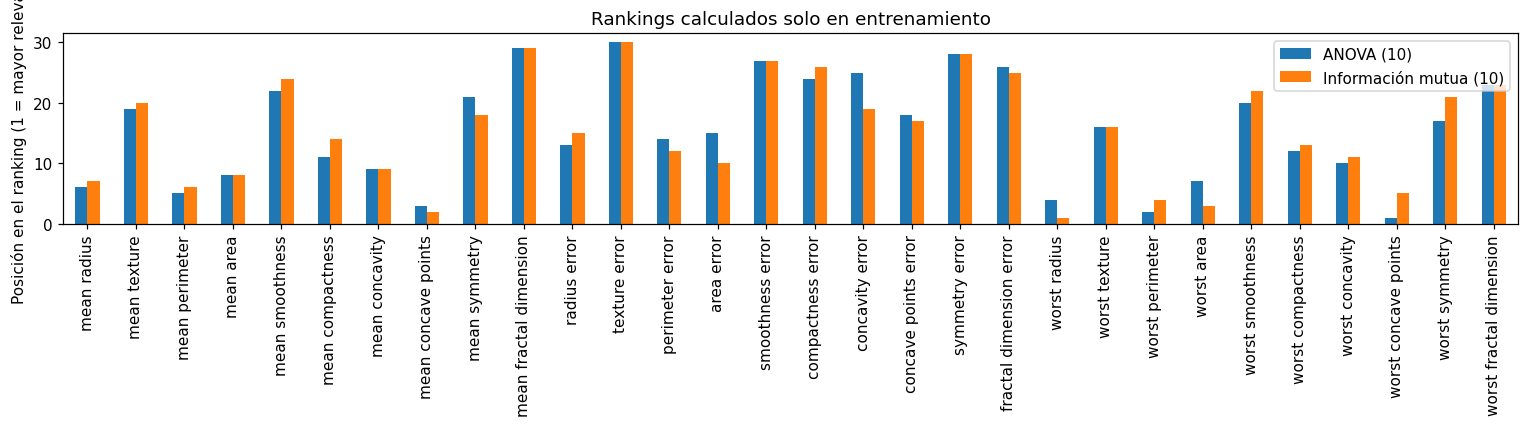

In [6]:
def informacion_mutua(X, y):
    return mutual_info_classif(X, y, random_state=SEED)

K = 10
selectores = {
    'ANOVA (10)': SelectKBest(f_classif, k=K),
    'Información mutua (10)': SelectKBest(informacion_mutua, k=K)
}
subconjuntos = {'Todas (30)': list(X.columns)}
ranking = pd.DataFrame(index=X.columns)
for nombre, selector in selectores.items():
    selector.fit(X_train, y_train)
    ranking[nombre] = selector.scores_
    subconjuntos[nombre] = X_train.columns[selector.get_support()].tolist()
display(ranking.sort_values('ANOVA (10)', ascending=False))
for nombre, variables in subconjuntos.items():
    print(nombre, ':', variables)
ranking.rank(ascending=False).plot.bar(figsize=(14, 4))
plt.ylabel('Posición en el ranking (1 = mayor relevancia)')
plt.title('Rankings calculados solo en entrenamiento')
plt.tight_layout()
plt.show()

## 5. Estabilidad de la selección

Se repiten los dos selectores sobre 20 submuestras estratificadas del 80 % de entrenamiento. La frecuencia indica sensibilidad al muestreo; no es una probabilidad de relevancia ni una evaluación independiente. Se informa también la estabilidad de las métricas ante tres semillas de la red, usando siempre las mismas semillas en todos los candidatos.

In [7]:
particiones = StratifiedShuffleSplit(n_splits=20, train_size=0.8, random_state=SEED)
frecuencias = pd.DataFrame(0.0, index=X.columns, columns=selectores)
for indices, _ in particiones.split(X_train, y_train):
    for nombre, funcion in [('ANOVA (10)', f_classif), ('Información mutua (10)', informacion_mutua)]:
        selector = SelectKBest(funcion, k=K).fit(X_train.iloc[indices], y_train.iloc[indices])
        frecuencias.loc[X.columns[selector.get_support()], nombre] += 1 / 20
display(frecuencias.sort_values('ANOVA (10)', ascending=False).round(2))
estabilidad = {nombre: frecuencias.loc[variables, nombre].mean()
               for nombre, variables in subconjuntos.items() if nombre in selectores}

,ANOVA (10),Información mutua (10)
mean radius,1.0,1.00
mean perimeter,1.0,1.00
mean area,1.0,1.00
mean concavity,1.0,1.00
mean concave points,1.0,1.00
worst radius,1.0,1.00
worst perimeter,1.0,1.00
worst area,1.0,1.00
worst concave points,1.0,1.00
worst concavity,0.8,0.15


In [8]:
def crear_rna(semilla=SEED):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPClassifier(hidden_layer_sizes=(10, 5), activation='relu',
                              max_iter=8000, random_state=semilla,
                              early_stopping=False, shuffle=True))
    ])

def metricas(y_real, pred):
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {'Accuracy': accuracy_score(y_real, pred),
            'Precisión': precision_score(y_real, pred, zero_division=0),
            'Recall': recall_score(y_real, pred, zero_division=0),
            'F1': f1_score(y_real, pred, zero_division=0),
            'FN': int(fn), 'FP': int(fp)}

modelos = {}
resultados = []
repeticiones = []
for nombre, selected_features in subconjuntos.items():
    for semilla in [42, 43, 44]:
        rna_clf = crear_rna(semilla)
        rna_clf.fit(X_train[selected_features], y_train)
        pred_val = rna_clf.predict(X_val[selected_features])
        medidas = metricas(y_val, pred_val)
        repeticiones.append({'Modelo': nombre, 'Semilla': semilla, **medidas})
        if semilla == SEED:
            modelos[nombre] = rna_clf
            resultados.append({'Modelo': nombre, 'Variables': len(selected_features),
                               **medidas, 'Iteraciones': rna_clf.named_steps['mlp'].n_iter_})
resultados_val = pd.DataFrame(resultados).set_index('Modelo')
display(resultados_val.round(4))
resumen_semillas = pd.DataFrame(repeticiones).groupby('Modelo')[['Recall', 'F1']].agg(['mean', 'std'])
display(resumen_semillas.round(4))

,Variables,Accuracy,Precisión,Recall,F1,FN,FP,Iteraciones
Modelo,,,,,,,,
Todas (30),30,0.9737,0.9545,0.9767,0.9655,1,2,473
ANOVA (10),10,0.9561,0.9524,0.9302,0.9412,3,2,265
Información mutua (10),10,0.9561,0.9524,0.9302,0.9412,3,2,305


Recall              F1        
                          mean     std    mean     std
Modelo                                                
ANOVA (10)              0.9380  0.0134  0.9528  0.0118
Información mutua (10)  0.9380  0.0134  0.9490  0.0136
Todas (30)              0.9767  0.0000  0.9768  0.0114

## 6. Elección final usando validación

Regla fijada para comparar: mayor recall de malignos; en empate, mayor F1; luego menos variables; finalmente mayor frecuencia media de selección. Se prioriza reducir falsos negativos. La comparación principal usa semilla 42; las otras semillas describen estabilidad, sin elegir la más favorable. El umbral de clasificación permanece en el valor predeterminado de 0,5.

La arquitectura oculta se mantiene constante; el número de conexiones de entrada cambia necesariamente al reducir variables.

In [9]:
tabla_eleccion = resultados_val.copy()
tabla_eleccion['Estabilidad'] = [estabilidad.get(n, 1.0) for n in tabla_eleccion.index]
tabla_eleccion = tabla_eleccion.sort_values(
    ['Recall', 'F1', 'Variables', 'Estabilidad'], ascending=[False, False, True, False], kind='stable')
nombre_elegido = tabla_eleccion.index[0]
selected_features = subconjuntos[nombre_elegido].copy()
display(tabla_eleccion.round(4))
print('Configuración congelada:', nombre_elegido)
print('Lista final de variables:', selected_features)
print('Reducción:', f'{100 * (1 - len(selected_features) / 30):.1f}%')
if nombre_elegido == 'Todas (30)':
    print('La reducción de variables no supera a la referencia según la regla establecida.')
else:
    print('Frecuencia media de las variables elegidas:', round(estabilidad[nombre_elegido], 3))

Configuración congelada: Todas (30)
Lista final de variables: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Reducción: 0.0%
La reducción de variables no supera a la referencia según la regla establecida.


,Variables,Accuracy,Precisión,Recall,F1,FN,FP,Iteraciones,Estabilidad
Modelo,,,,,,,,,
Todas (30),30,0.9737,0.9545,0.9767,0.9655,1,2,473,1.000
Información mutua (10),10,0.9561,0.9524,0.9302,0.9412,3,2,305,0.985
ANOVA (10),10,0.9561,0.9524,0.9302,0.9412,3,2,265,0.980


## 7. Evaluación final en prueba

Se evalúan una única vez el modelo elegido y la referencia con 30 variables (si coinciden, se evalúa uno solo). Se reutilizan los modelos entrenados con entrenamiento: no se reajustan selectores ni escaladores y no se modifica la configuración después de ver prueba. Esto mantiene la selección limitada a entrenamiento y facilita comparar validación y prueba con el mismo modelo.

En la matriz, las filas son clases reales y las columnas predichas: **FN = real maligno, predicho benigno**. Esos casos son el error especialmente relevante en esta consigna.

Modelo: Todas (30)
              precision    recall  f1-score   support

     Benigno       0.96      0.99      0.97        72
     Maligno       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



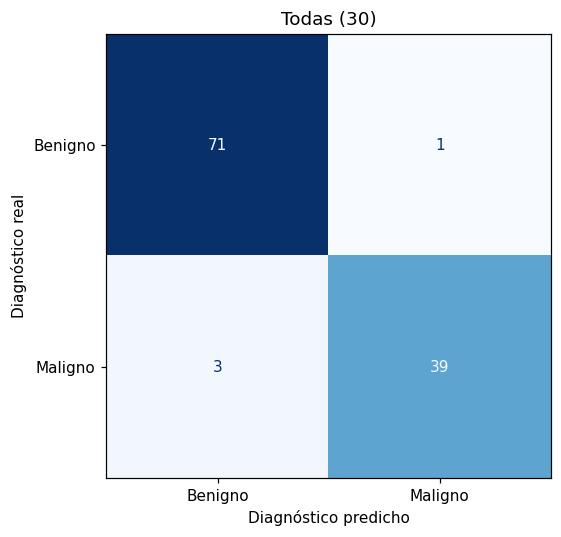

,Accuracy,Precisión,Recall,F1,FN,FP
Modelo,,,,,,
Todas (30),0.9649,0.975,0.9286,0.9512,3,1


In [10]:
nombres_finales = list(dict.fromkeys(['Todas (30)', nombre_elegido]))
resultados_test = []
fig, axes = plt.subplots(1, len(nombres_finales), figsize=(6 * len(nombres_finales), 5), squeeze=False)
for ax, nombre in zip(axes.ravel(), nombres_finales):
    pred_test = modelos[nombre].predict(X_test[subconjuntos[nombre]])
    resultados_test.append({'Modelo': nombre, **metricas(y_test, pred_test)})
    print('Modelo:', nombre)
    print(classification_report(y_test, pred_test, labels=[0, 1],
                                target_names=['Benigno', 'Maligno'], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, labels=[0, 1],
        display_labels=['Benigno', 'Maligno'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel('Diagnóstico predicho')
    ax.set_ylabel('Diagnóstico real')
plt.tight_layout()
plt.show()
resultados_test = pd.DataFrame(resultados_test).set_index('Modelo')
display(resultados_test.round(4))

## 8. Conclusión y límites

Los valores siguientes se generan a partir de la ejecución, sin resultados escritos manualmente. Una alta asociación univariada no garantiza información complementaria: radio, área y perímetro pueden aparecer juntos en los rankings. Las frecuencias permiten observar qué variables se reemplazan entre sí al cambiar la muestra.

No hay selección ni escalado sobre prueba. La elección entre tres representaciones usa validación y puede adaptarse a esa muestra; por eso el resultado de prueba se informa sin volver a elegir. La estabilidad de selectores y semillas es descriptiva y no reemplaza validación cruzada anidada ni evaluación externa.

In [11]:
fila_val = resultados_val.loc[nombre_elegido]
fila_test = resultados_test.loc[nombre_elegido]
texto = (
    f'**Modelo elegido:** {nombre_elegido}, con {len(selected_features)} variables. '
    f'En validación obtuvo recall de malignos {fila_val["Recall"]:.3f} y F1 {fila_val["F1"]:.3f}. '
    f'En prueba obtuvo accuracy {fila_test["Accuracy"]:.3f}, precisión {fila_test["Precisión"]:.3f}, '
    f'recall {fila_test["Recall"]:.3f} y F1 {fila_test["F1"]:.3f}; '
    f'dejó {int(fila_test["FN"])} casos malignos sin detectar y produjo {int(fila_test["FP"])} falsos positivos. '
    'La decisión se tomó antes de consultar prueba. Estos resultados corresponden a una partición '
    'pequeña del dataset y no permiten afirmar utilidad clínica.'
)
display(Markdown(texto))
print('Variables finales:', ', '.join(selected_features))

Variables finales: mean radius, mean texture, mean perimeter, mean area, mean smoothness, mean compactness, mean concavity, mean concave points, mean symmetry, mean fractal dimension, radius error, texture error, perimeter error, area error, smoothness error, compactness error, concavity error, concave points error, symmetry error, fractal dimension error, worst radius, worst texture, worst perimeter, worst area, worst smoothness, worst compactness, worst concavity, worst concave points, worst symmetry, worst fractal dimension


**Modelo elegido:** Todas (30), con 30 variables. En validación obtuvo recall de malignos 0.977 y F1 0.966. En prueba obtuvo accuracy 0.965, precisión 0.975, recall 0.929 y F1 0.951; dejó 3 casos malignos sin detectar y produjo 1 falsos positivos. La decisión se tomó antes de consultar prueba. Estos resultados corresponden a una partición pequeña del dataset y no permiten afirmar utilidad clínica.